# Unit 3 · Exercise 3: Multiple linear regression

Executed learning workbook, prepared 5 November 2026. Adapted from the supplied University of Essex Online notebook. The original examples appear first, followed by controlled experiments and interpretation.

**How to use:** Run all cells from top to bottom. Find **Change these values**, change one setting, then run all again. Keep the random seed fixed when comparing a change in noise or model settings. Read the printed results alongside the plots; outputs describe these teaching datasets only.

**Corrections and provenance:** The attachment omitted cars.csv. This workbook supplies and embeds the W3Schools teaching dataset (36 rows), which reproduces the coefficients and predictions printed in the original notebook; it is not independently verified emissions evidence. The original CSV title differs (data.csv); the bundled copy is named cars.csv. Predictions use named feature columns. CO2 is expressed as g/km, not total grams.

The supplied activity specifies running and varying four programs; it does not specify an essay word count or a separate submission format. These notebooks provide execution evidence and observations. Review and personalise the final reflection prompts yourself.

## 1. Original example (corrected where needed)

**Execution note:** All code cells were executed in order in a fresh local IPython session, with actual printed results and figures captured below. This environment does not permit the socket-based Jupyter kernel launcher. Rerun in your own Jupyter or Colab session for your course workflow.

In [1]:
import pandas
from sklearn import linear_model

from io import StringIO
# Embedded copy of https://www.w3schools.com/python/data.csv
# No separate upload or internet connection is needed to run this notebook.
CSV_DATA = 'Car,Model,Volume,Weight,CO2\nToyoty,Aygo,1000,790,99\nMitsubishi,Space Star,1200,1160,95\nSkoda,Citigo,1000,929,95\nFiat,500,900,865,90\nMini,Cooper,1500,1140,105\nVW,Up!,1000,929,105\nSkoda,Fabia,1400,1109,90\nMercedes,A-Class,1500,1365,92\nFord,Fiesta,1500,1112,98\nAudi,A1,1600,1150,99\nHyundai,I20,1100,980,99\nSuzuki,Swift,1300,990,101\nFord,Fiesta,1000,1112,99\nHonda,Civic,1600,1252,94\nHundai,I30,1600,1326,97\nOpel,Astra,1600,1330,97\nBMW,1,1600,1365,99\nMazda,3,2200,1280,104\nSkoda,Rapid,1600,1119,104\nFord,Focus,2000,1328,105\nFord,Mondeo,1600,1584,94\nOpel,Insignia,2000,1428,99\nMercedes,C-Class,2100,1365,99\nSkoda,Octavia,1600,1415,99\nVolvo,S60,2000,1415,99\nMercedes,CLA,1500,1465,102\nAudi,A4,2000,1490,104\nAudi,A6,2000,1725,114\nVolvo,V70,1600,1523,109\nBMW,5,2000,1705,114\nMercedes,E-Class,2100,1605,115\nVolvo,XC70,2000,1746,117\nFord,B-Max,1600,1235,104\nBMW,216,1600,1390,108\nOpel,Zafira,1600,1405,109\nMercedes,SLK,2500,1395,120\n'
df = pandas.read_csv(StringIO(CSV_DATA))

X = df[['Weight', 'Volume']]
y = df['CO2']

regr = linear_model.LinearRegression()
regr.fit(X, y)

#predict the CO2 emission of a car where the weight is 2300kg, and the volume is 1300cm3:
predictedCO2 = regr.predict(pandas.DataFrame([[2300, 1300]], columns=['Weight', 'Volume']))

print(predictedCO2)

[107.2087328]


# Coefficient

The coefficient is a factor that describes the relationship with an unknown variable.
In this case, we can ask for the coefficient value of weight against CO2, and for volume against CO2. The answer(s) we get tells us what would happen if we increase, or decrease, one of the independent values.

In [2]:
print(regr.coef_)

[0.00755095 0.00780526]


The coefficients are approximately 0.00755095 g/km per kg of weight and 0.00780526 g/km per cm³ of engine volume, **holding the other predictor fixed**. These describe fitted associations, not causal effects. The model predicts 107.2087 g/km at 2300 kg and 1300 cm³ and 114.7597 g/km at 3300 kg and 1300 cm³. Both weights exceed the observed training range, so these are extrapolations. The numerical difference illustrates the linear equation, not physical validation.

In [3]:
predictedCO2 = regr.predict(pandas.DataFrame([[3300, 1300]], columns=['Weight', 'Volume']))

print(predictedCO2)

[114.75968007]


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2, 'font.size': 10})

## 2. Vary predictors and change training data
Changing a prediction input is different from changing a training observation and refitting. This section demonstrates both. The working prediction (1400 kg, 1600 cm³) lies within the marginal data ranges, although that alone cannot establish reliability.

Dataset shape: (36, 5)
Observed ranges:
Baseline coefficients: [0.00755095 0.00780526]


,Weight,Volume,CO2
min,790,900,90
max,1746,2500,120


,Weight,Volume,Predicted CO2 (g/km)
Chosen case,1400,1600,102.7545
Increase weight only,1600,1600,104.2646
Increase volume only,1400,2000,105.8766


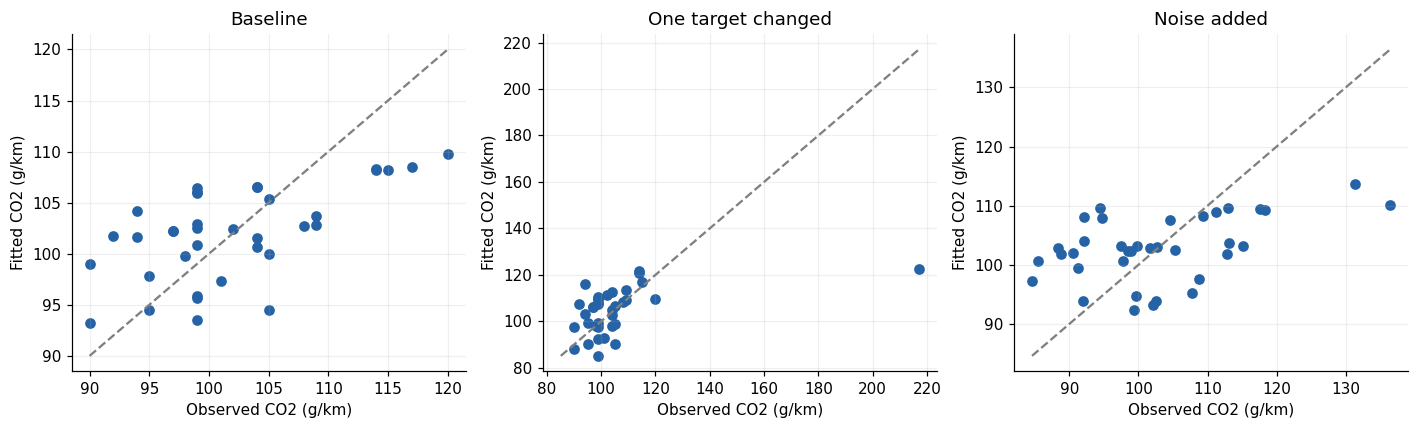

,Scenario,Weight coefficient,Volume coefficient,Intercept,Training R2,Chosen-case prediction
0,Baseline,0.00755,0.00781,79.69472,0.37656,102.75446
1,One target changed,0.03815,0.00080,54.22382,0.21419,108.90594
2,Noise added,0.00480,0.01180,77.56220,0.21461,103.15175


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
# Change these values, then run all cells again.
PREDICT_WEIGHT = 1400
PREDICT_VOLUME = 1600
WEIGHT_INCREASE = 200
VOLUME_INCREASE = 400
OUTLIER_CO2_INCREASE = 100
TARGET_NOISE_SD = 10
RANDOM_SEED = 42
features=['Weight','Volume']
X0=df[features]; y0=df['CO2']
base=LinearRegression().fit(X0,y0)
print('Dataset shape:',df.shape)
print('Observed ranges:'); display(df[features+['CO2']].agg(['min','max']))
print('Baseline coefficients:',base.coef_)
queries=pd.DataFrame([[PREDICT_WEIGHT,PREDICT_VOLUME],
                      [PREDICT_WEIGHT+WEIGHT_INCREASE,PREDICT_VOLUME],
                      [PREDICT_WEIGHT,PREDICT_VOLUME+VOLUME_INCREASE]],columns=features,
                     index=['Chosen case','Increase weight only','Increase volume only'])
queries['Predicted CO2 (g/km)']=base.predict(queries[features])
display(queries.round(4))
changed=y0.copy().astype(float)
changed.loc[df['Weight'].idxmax()] += OUTLIER_CO2_INCREASE
noisy=y0+np.random.default_rng(RANDOM_SEED).normal(0,TARGET_NOISE_SD,len(y0))
rows=[]
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,(name,target) in zip(axes,{'Baseline':y0,'One target changed':changed,'Noise added':noisy}.items()):
    model=LinearRegression().fit(X0,target)
    predictions=model.predict(X0)
    rows.append({'Scenario':name,'Weight coefficient':model.coef_[0], 'Volume coefficient':model.coef_[1],
                 'Intercept':model.intercept_,'Training R2':r2_score(target,predictions),
                 'Chosen-case prediction':model.predict(queries[features].iloc[[0]])[0]})
    ax.scatter(target,predictions,color='#2563a6')
    low=min(min(target),min(predictions)); high=max(max(target),max(predictions))
    ax.plot([low,high],[low,high],'--',color='gray')
    ax.set(title=name,xlabel='Observed CO2 (g/km)',ylabel='Fitted CO2 (g/km)')
fig.tight_layout(); plt.show()
multiple_results=pd.DataFrame(rows); display(multiple_results.round(5))

## 3. Does another predictor improve generalisation?
Use the same held-out rows for all three models. The test set is only nine cars, so the scores are unstable and illustrative. We do not tune a model on these test results or present them as deployment evidence.

In [6]:
train_idx,test_idx=train_test_split(np.arange(len(df)),test_size=0.25,random_state=RANDOM_SEED)
scores=[]
for columns in [['Weight'],['Volume'],['Weight','Volume']]:
    model=LinearRegression().fit(df.iloc[train_idx][columns],y0.iloc[train_idx])
    test_pred=model.predict(df.iloc[test_idx][columns])
    scores.append({'Predictors':' + '.join(columns),
                   'Training R2':model.score(df.iloc[train_idx][columns],y0.iloc[train_idx]),
                   'Test R2':r2_score(y0.iloc[test_idx],test_pred),
                   'Test RMSE (g/km)':np.sqrt(mean_squared_error(y0.iloc[test_idx],test_pred))})
multiple_holdout=pd.DataFrame(scores); display(multiple_holdout.round(4))
print('Predictor correlation:',df['Weight'].corr(df['Volume']))

Predictor correlation: 0.7535372689189782


,Predictors,Training R2,Test R2,Test RMSE (g/km)
0,Weight,0.2312,0.2452,7.9201
1,Volume,0.2197,0.3839,7.1557
2,Weight + Volume,0.2560,0.3780,7.1902


## 4. Interpretation
Holding engine volume fixed, a 200 kg increase changes the fitted prediction by 200 times the weight coefficient. This is not the same as adding heavier cars to the training data. The changed-target experiment shows sensitivity to one observation; the noisy-target experiment tests measurement error. Adding predictors can improve training fit without reliably improving unseen-case performance. Correlated predictors can make individual coefficient interpretations harder.

**Try next:** Change OUTLIER_CO2_INCREASE from 100 to 20. Change PREDICT_WEIGHT from 1400 to 3300 and compare it with the displayed training range. Do not interpret extrapolated CO2 values as real emissions measurements or regulatory evidence.

## Professional interpretation and personal reflection

- **Dataset suitability:** These are synthetic or small teaching datasets. A strong fit does not establish representativeness, causation or fitness for operational use.
- **Ethical and social issues:** Do not remove inconvenient outliers to improve a score. Investigate whether they are errors or valid cases; rare cases can matter disproportionately in real decisions. Report uncertainty and subgroup limitations.
- **Legal and professional issues:** Before using real personal data, establish the applicable permission or lawful basis, privacy safeguards and data-use terms. These examples do not demonstrate legal compliance. Preserve provenance, units, changes and reproducible execution evidence.
- **Your reflection:** Which change did you rerun? What did you expect, what actually changed, and what would you check before using the model for a real decision? Write your own answers after inspecting the results.

## References and dataset provenance
University of Essex Online (2026) *Unit03 Ex3 multiple_linear_regression* [teaching notebook supplied with the activity].

W3Schools (n.d.) *Python machine learning: multiple regression*. Available at: https://www.w3schools.com/python/python_ml_multiple_regression.asp (Accessed: 5 November 2026). Teaching CSV: https://www.w3schools.com/python/data.csv. The data are supplied for testing, not independently validated research.

Scikit-learn developers (n.d.) *LinearRegression*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html (Accessed: 5 November 2026).